In [1]:
import numpy as np
import pandas as pd
import random
import hashlib
import os
import json
import matplotlib.pyplot as plt

from collections import defaultdict
from cryptography.hazmat.primitives.ciphers.aead import AESGCM

import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

print("Libraries imported successfully.")

C:\Users\DELL\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (
In C:\Users\DELL\anaconda3\Lib\site-packages\matplotlib\mpl-data\stylelib\bmh.mplstyle: The text.hinting_factor rcParam was deprecated in Matplotlib 3.11 and will be removed in 3.13.
In C:\Users\DELL\anaconda3\Lib\site-packages\matplotlib\mpl-data\stylelib\classic.mplstyle: The text.hinting_factor rcParam was deprecated in Matplotlib 3.11 and will be removed in 3.13.
In C:\Users\DELL\anaconda3\Lib\site-packages\matplotlib\mpl-data\stylelib\_classic_test_patch.mplstyle: The text.kerning_factor rcParam was deprecated in Matplotlib 3.11 and will be removed in 3.13.


Libraries imported successfully.


In [2]:
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager

# Use a standard Matplotlib font
matplotlib.rcParams["font.family"] = "DejaVu Sans"
matplotlib.rcParams["font.sans-serif"] = ["DejaVu Sans"]

# Disable the missing fallback font
matplotlib.rcParams["font.enable_last_resort"] = False

# Avoid problematic font fallback
matplotlib.rcParams["axes.unicode_minus"] = False

# Check the font
font_path = font_manager.findfont("DejaVu Sans")

print("Matplotlib version:", matplotlib.__version__)
print("Font available:", font_path)
print("Matplotlib font configuration updated.")

Matplotlib version: 3.11.2
Font available: C:\Users\DELL\anaconda3\Lib\site-packages\matplotlib\mpl-data\fonts\ttf\DejaVuSans.ttf
Matplotlib font configuration updated.


In [3]:
NUM_NODES = 200
AREA = 1000

INITIAL_ENERGY = 2.0

NUM_TRIALS = 30
MAX_ROUNDS = 1000

BASE_STATION = (500, 500)

TX_ENERGY = 0.00005
RX_ENERGY = 0.00002

N_QUBITS = 4096
E_QUBIT = 0.000001

QBER_THRESHOLD = 0.15
QBER_TEST_FRACTION = 0.25

CHANNEL_ERROR_RATE = 0.05

PROTOCOLS = [
    "EA-QKD",
    "PQ-LEACH",
    "QSEER",
    "IHKEM"
]

print("Simulation parameters initialized.")

Simulation parameters initialized.


In [4]:
def create_nodes(seed):

    np.random.seed(seed)

    nodes = []

    for i in range(NUM_NODES):

        node = {
            "id": i,
            "x": np.random.uniform(0, AREA),
            "y": np.random.uniform(0, AREA),
            "energy": INITIAL_ENERGY,
            "alive": True,
            "cluster_head": False
        }

        nodes.append(node)

    return nodes

In [5]:
def calculate_distance(node1, node2):

    return np.sqrt(
        (node1["x"] - node2["x"])**2 +
        (node1["y"] - node2["y"])**2
    )

In [6]:
def consume_energy(node, energy):

    if not node["alive"]:
        return False

    if node["energy"] <= energy:

        node["energy"] = 0
        node["alive"] = False

        return False

    node["energy"] -= energy

    return True

In [7]:
def simulate_bb84_qber(seed, channel_error_rate):

    rng = np.random.default_rng(seed)

    alice_bits = rng.integers(0, 2, N_QUBITS)
    alice_basis = rng.integers(0, 2, N_QUBITS)
    bob_basis = rng.integers(0, 2, N_QUBITS)

    matching = alice_basis == bob_basis

    sifted_alice = alice_bits[matching]

    bob_bits = sifted_alice.copy()

    errors = rng.random(len(bob_bits)) < channel_error_rate

    bob_bits = np.bitwise_xor(
        bob_bits,
        errors.astype(int)
    )

    if len(sifted_alice) < 2:
        return np.nan, False, 0

    test_size = max(
        1,
        int(len(sifted_alice) * QBER_TEST_FRACTION)
    )

    test_indices = rng.choice(
        len(sifted_alice),
        size=test_size,
        replace=False
    )

    qber = np.mean(
        sifted_alice[test_indices] != bob_bits[test_indices]
    )

    accepted = qber <= QBER_THRESHOLD

    return qber * 100, accepted, len(sifted_alice) - test_size

In [8]:
def generate_session_key(seed, node_id):

    random_data = os.urandom(32)

    material = (
        str(seed).encode() +
        str(node_id).encode() +
        random_data
    )

    return hashlib.sha256(material).digest()

In [9]:
def aes_gcm_test(key, plaintext):

    aesgcm = AESGCM(key)

    nonce = os.urandom(12)

    ciphertext = aesgcm.encrypt(
        nonce,
        plaintext,
        None
    )

    decrypted = aesgcm.decrypt(
        nonce,
        ciphertext,
        None
    )

    return decrypted == plaintext

In [10]:
def route_to_gateway(nodes, source_id):

    source = nodes[source_id]

    if not source["alive"]:
        return False, 0, 0

    gateway = {
        "x": BASE_STATION[0],
        "y": BASE_STATION[1]
    }

    current = source
    visited = {source_id}

    hops = 0
    total_energy = 0

    while True:

        distance_gateway = calculate_distance(
            current,
            gateway
        )

        candidates = []

        for node in nodes:

            if not node["alive"]:
                continue

            if node["id"] in visited:
                continue

            distance = calculate_distance(current, node)

            if distance < distance_gateway:
                candidates.append(node)

        if not candidates:

            energy = TX_ENERGY * distance_gateway / AREA

            consume_energy(current, energy)

            total_energy += energy

            return True, hops + 1, total_energy

        next_node = min(
            candidates,
            key=lambda n: calculate_distance(current, n)
        )

        tx = TX_ENERGY
        rx = RX_ENERGY

        if not consume_energy(current, tx):
            return False, hops, total_energy

        if not consume_energy(next_node, rx):
            return False, hops, total_energy

        total_energy += tx + rx

        current = next_node

        visited.add(current["id"])

        hops += 1

        if hops >= NUM_NODES:
            return False, hops, total_energy

In [11]:
def select_cluster_heads(nodes, protocol, rng):

    alive_nodes = [
        node for node in nodes
        if node["alive"]
    ]

    if not alive_nodes:
        return []

    number_of_heads = max(
        1,
        int(len(alive_nodes) * 0.05)
    )

    selected = rng.choice(
        len(alive_nodes),
        size=min(number_of_heads, len(alive_nodes)),
        replace=False
    )

    heads = []

    for node in alive_nodes:

        node["cluster_head"] = False

    for index in selected:

        node = alive_nodes[index]

        node["cluster_head"] = True

        heads.append(node)

    return heads

In [12]:

def simulate_network_round(
    nodes,
    protocol,
    rng,
    distance_matrix,
    gateway_distances
):

    alive_nodes = [
        node for node in nodes if node["alive"]
    ]

    if not alive_nodes:
        return 0, 0, 0

    heads = select_cluster_heads(nodes, protocol, rng)

    packets_sent = 0
    packets_delivered = 0
    round_energy = 0.0

    alive_mask = np.array(
        [node["alive"] for node in nodes],
        dtype=bool
    )

    for source in alive_nodes:

        source_id = source["id"]

        if not source["alive"] or source["cluster_head"]:
            continue

        packets_sent += 1

        current_id = source_id
        visited = np.zeros(NUM_NODES, dtype=bool)

        success = False
        hops = 0

        while hops < NUM_NODES:

            if not alive_mask[current_id]:
                break

            visited[current_id] = True

            candidates = (
                alive_mask
                & (~visited)
                & (gateway_distances < gateway_distances[current_id])
            )

            candidate_ids = np.flatnonzero(candidates)

            if len(candidate_ids) == 0:

                direct_energy = (
                    TX_ENERGY *
                    gateway_distances[current_id] / AREA
                )

                if consume_energy(
                    nodes[current_id],
                    direct_energy
                ):

                    round_energy += direct_energy
                    alive_mask[current_id] = nodes[current_id]["alive"]
                    success = True

                else:
                    alive_mask[current_id] = False

                break

            distances = distance_matrix[
                current_id,
                candidate_ids
            ]

            next_id = candidate_ids[np.argmin(distances)]

            tx_success = consume_energy(
                nodes[current_id],
                TX_ENERGY
            )

            if not tx_success:
                alive_mask[current_id] = False
                break

            round_energy += TX_ENERGY

            alive_mask[current_id] = nodes[current_id]["alive"]

            rx_success = consume_energy(
                nodes[next_id],
                RX_ENERGY
            )

            if not rx_success:
                alive_mask[next_id] = False
                break

            round_energy += RX_ENERGY

            alive_mask[next_id] = nodes[next_id]["alive"]

            current_id = next_id
            hops += 1

        if success:
            packets_delivered += 1

    return packets_sent, packets_delivered, round_energy


In [13]:

def simulate_trial(protocol, seed):

    rng = np.random.default_rng(seed)

    nodes = create_nodes(seed)

    # Calculate distances only once per trial
    coordinates = np.array([
        [node["x"], node["y"]]
        for node in nodes
    ])

    differences = (
        coordinates[:, None, :] -
        coordinates[None, :, :]
    )

    distance_matrix = np.sqrt(
        np.sum(differences ** 2, axis=2)
    )

    gateway_distances = np.sqrt(
        (coordinates[:, 0] - BASE_STATION[0]) ** 2 +
        (coordinates[:, 1] - BASE_STATION[1]) ** 2
    )

    alive_history = []

    total_energy = 0.0
    total_packets = 0
    delivered_packets = 0

    first_node_death = None
    half_node_death = None
    last_node_death = None

    total_delay = []

    for round_number in range(1, MAX_ROUNDS + 1):

        sent, delivered, energy = simulate_network_round(
            nodes,
            protocol,
            rng,
            distance_matrix,
            gateway_distances
        )

        total_packets += sent
        delivered_packets += delivered
        total_energy += energy

        total_delay.append(
            2.0 * (sent / max(delivered, 1))
        )

        alive_count = sum(
            node["alive"] for node in nodes
        )

        alive_history.append(alive_count)

        if alive_count < NUM_NODES and first_node_death is None:
            first_node_death = round_number

        if alive_count <= NUM_NODES / 2 and half_node_death is None:
            half_node_death = round_number

        if alive_count == 0:
            last_node_death = round_number
            break

    # BB84 evaluation
    qber, key_accepted, retained_bits = simulate_bb84_qber(
        seed,
        CHANNEL_ERROR_RATE
    )

    qkd_energy = N_QUBITS * E_QUBIT

    if protocol == "EA-QKD":
        total_energy += qkd_energy

    key_success = 0

    if key_accepted:

        for node in nodes:

            key = generate_session_key(
                seed,
                node["id"]
            )

            plaintext = b"Secure WSN communication"

            if aes_gcm_test(key, plaintext):
                key_success += 1

    pdr = (
        delivered_packets / total_packets * 100
        if total_packets > 0 else 0
    )

    average_delay = (
        float(np.mean(total_delay))
        if total_delay else 0
    )

    return {
        "Protocol": protocol,
        "Trial": seed,
        "Energy": total_energy,
        "FND": first_node_death,
        "PDR": pdr,
        "Delay": average_delay,
        "QBER": qber,
        "Key_Accepted": int(key_accepted),
        "AES_Verified_Nodes": key_success,
        "Alive_History": alive_history
    }


In [24]:

import time
import pandas as pd

all_results = []

start_time = time.perf_counter()

for p_idx, protocol in enumerate(PROTOCOLS):

    print(f"\nStarting protocol: {protocol}", flush=True)

    for trial in range(NUM_TRIALS):

        seed = 20261120 + p_idx * 100000 + trial

        trial_start = time.perf_counter()

        result = simulate_trial(protocol, seed)

        all_results.append(result)

        # Save checkpoint after every trial
        checkpoint_df = pd.DataFrame(all_results)

        checkpoint_df.to_pickle(
            "ea_qkd_checkpoint.pkl"
        )

        # Also save CSV
        checkpoint_df.to_csv(
            "ea_qkd_network_trial_results_partial.csv",
            index=False
        )

        elapsed = time.perf_counter() - trial_start

        print(
            f"{protocol}: Trial {trial + 1}/{NUM_TRIALS} "
            f"| Time: {elapsed:.2f} seconds "
            f"| Completed: {len(all_results)}/"
            f"{len(PROTOCOLS) * NUM_TRIALS}",
            flush=True
        )

total_time = time.perf_counter() - start_time

print("\nAll simulations completed.")
print(f"Total execution time: {total_time / 60:.2f} minutes")



Starting protocol: EA-QKD
EA-QKD: Trial 1/30 | Time: 26.35 seconds | Completed: 1/120
EA-QKD: Trial 2/30 | Time: 27.73 seconds | Completed: 2/120
EA-QKD: Trial 3/30 | Time: 28.34 seconds | Completed: 3/120
EA-QKD: Trial 4/30 | Time: 28.30 seconds | Completed: 4/120
EA-QKD: Trial 5/30 | Time: 27.89 seconds | Completed: 5/120
EA-QKD: Trial 6/30 | Time: 29.14 seconds | Completed: 6/120
EA-QKD: Trial 7/30 | Time: 26.82 seconds | Completed: 7/120
EA-QKD: Trial 8/30 | Time: 26.64 seconds | Completed: 8/120
EA-QKD: Trial 9/30 | Time: 27.30 seconds | Completed: 9/120
EA-QKD: Trial 10/30 | Time: 26.00 seconds | Completed: 10/120
EA-QKD: Trial 11/30 | Time: 29.71 seconds | Completed: 11/120
EA-QKD: Trial 12/30 | Time: 26.92 seconds | Completed: 12/120
EA-QKD: Trial 13/30 | Time: 28.62 seconds | Completed: 13/120
EA-QKD: Trial 14/30 | Time: 27.13 seconds | Completed: 14/120
EA-QKD: Trial 15/30 | Time: 26.62 seconds | Completed: 15/120
EA-QKD: Trial 16/30 | Time: 28.15 seconds | Completed: 16/120

In [27]:
metrics = [
    "Energy",
    "FND",
    "PDR",
    "Delay"
]

summary = results_df.groupby("Protocol")[metrics].agg(
    ["mean", "std"]
)

print(summary)

              Energy                   FND                   PDR            \
                mean       std        mean        std       mean       std   
Protocol                                                                     
EA-QKD    120.902917  5.786270  276.033333  70.036189  99.986602  0.002178   
IHKEM     121.620438  5.361385  267.166667  60.496271  99.987353  0.001737   
PQ-LEACH  122.939410  6.411787  271.300000  71.569185  99.986928  0.002128   
QSEER     121.533842  5.510229  278.300000  71.445735  99.987169  0.001890   

             Delay            
              mean       std  
Protocol                      
EA-QKD    2.000276  0.000046  
IHKEM     2.000260  0.000037  
PQ-LEACH  2.000269  0.000046  
QSEER     2.000264  0.000040  


In [28]:
qber_records = []

ERROR_RATES = [0.02, 0.05, 0.08, 0.12]

for error_rate in ERROR_RATES:

    for trial in range(NUM_TRIALS):

        seed = 500000 + trial

        qber, accepted, retained_bits = simulate_bb84_qber(
            seed,
            error_rate
        )

        qber_records.append({

            "Channel_Error_Rate": error_rate * 100,
            "Trial": trial + 1,
            "QBER": qber,
            "Accepted": int(accepted),
            "Retained_Key_Bits": retained_bits

        })

qber_df = pd.DataFrame(qber_records)

qber_df.to_csv(
    "ea_qkd_qber_trial_records.csv",
    index=False
)

print(qber_df.groupby("Channel_Error_Rate").agg(
    QBER_Mean=("QBER", "mean"),
    QBER_SD=("QBER", "std"),
    Acceptance_Rate=("Accepted", "mean")
))

                    QBER_Mean   QBER_SD  Acceptance_Rate
Channel_Error_Rate                                      
2.0                  2.081550  0.472801         1.000000
5.0                  4.949210  0.864782         1.000000
8.0                  7.808856  1.035098         1.000000
12.0                12.147928  1.350123         0.966667


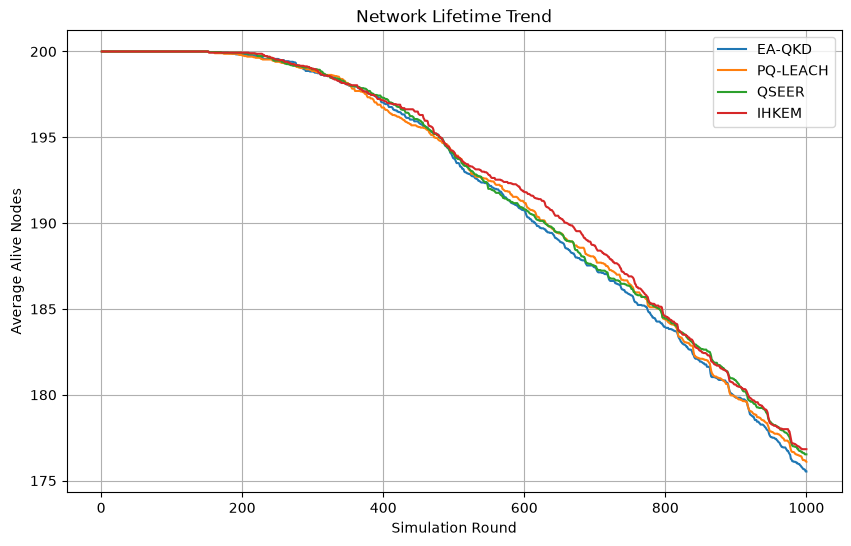

In [31]:
plt.figure(figsize=(10, 6))

for protocol in PROTOCOLS:

    subset = results_df[
        results_df["Protocol"] == protocol
    ]

    histories = subset["Alive_History"].tolist()

    max_length = max(map(len, histories))

    padded = np.array([
        history + [history[-1]] * (max_length - len(history))
        for history in histories
    ])

    average_alive = np.mean(padded, axis=0)

    plt.plot(
        range(1, len(average_alive) + 1),
        average_alive,
        label=protocol
    )

plt.xlabel("Simulation Round")
plt.ylabel("Average Alive Nodes")
plt.title("Network Lifetime Trend")
plt.legend()
plt.grid(True)
plt.show()

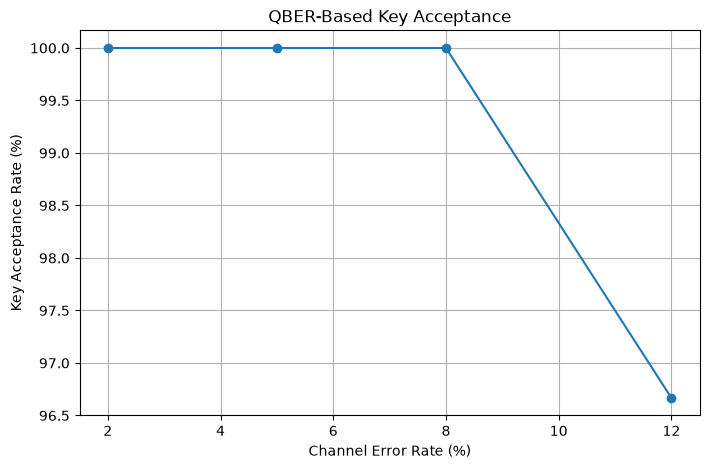

In [33]:
acceptance = qber_df.groupby(
    "Channel_Error_Rate"
)["Accepted"].mean() * 100

plt.figure(figsize=(8, 5))

plt.plot(
    acceptance.index,
    acceptance.values,
    marker="o"
)

plt.xlabel("Channel Error Rate (%)")
plt.ylabel("Key Acceptance Rate (%)")

plt.title("QBER-Based Key Acceptance")

plt.grid(True)
plt.show()

In [34]:
summary.to_csv(
    "ea_qkd_final_summary.csv"
)

print("All output files generated:")
print("1. ea_qkd_network_trial_results.csv")
print("2. ea_qkd_qber_trial_records.csv")
print("3. ea_qkd_final_summary.csv")

All output files generated:
1. ea_qkd_network_trial_results.csv
2. ea_qkd_qber_trial_records.csv
3. ea_qkd_final_summary.csv
